# Sales Prediction Using Python
## Advertising Spend and Sales

**Objective:** Build and compare regression models that predict product sales using advertising expenditure across TV, Radio, and Newspaper channels.

**Dataset:** `Advertising.csv`  
**Tools:** Python, pandas, scikit-learn, Matplotlib, Seaborn

### Project workflow
1. Load and inspect the dataset
2. Clean column names and check data quality
3. Perform exploratory data analysis (EDA)
4. Visualize relationships and correlations
5. Split data into training and testing sets
6. Train Linear Regression and Random Forest models
7. Evaluate models using MAE, RMSE, and R²
8. Inspect residuals and interpret advertising-channel impact

# 1. Import libraries

In [1]:
# Data manipulation 
import pandas as pd
import numpy as np

# data visualisation 
import matplotlib.pyplot as plt
import seaborn as sns

# data split 
from sklearn.model_selection import train_test_split

# data models 
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# model evaluations 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# 2. Load the dataset

This section include loading the *Advertising Dataset* into a pandas DataFrame 

In [ ]:
# read the dataset 
df = pd.read_csv("Advertising.csv")

# view the head and shape 
print("Dataset shape:", df.shape, "\n")
display(df.head())

Dataset shape: (200, 5) 



,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [3]:
# The classic dataset may contain an unnecessary index column.
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

### Preliminary findings

- The classic Advertising dataset contains 200 observations.
- `TV`, `Radio`, and `Newspaper` are the predictor variables.
- `Sales` is the target variable.
- The index-like `Unnamed: 0` column, when present, is removed because it is not an advertising feature.

# 3. Data inspection and quality checks

This section examine the columns, missing values, data type, descriptive statistics, and duplicated values in the dataset 

In [21]:
# the columns name 
print("Column names:", df.columns.tolist())

# view data types
print("\n Data types:")
display(df.dtypes.to_frame("Data type"))

# check missing values 
print("\n Missing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

# check duplicated value  
print("\n Duplicate rows:", df.duplicated().sum())

# descriptive statistics 
print("\n Descriptive statistics:")
display(df.describe().T)

Column names: ['TV', 'Radio', 'Newspaper', 'Sales']

Data types:


,Data type
TV,float64
Radio,float64
Newspaper,float64
Sales,float64



Missing values per column:


,Missing values
TV,0
Radio,0
Newspaper,0
Sales,0



 Duplicate rows: 0

 Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
TV,200.0,147.0425,85.854236,0.7,74.375,149.75,218.825,296.4
Radio,200.0,23.2640,14.846809,0.0,9.975,22.90,36.525,49.6
Newspaper,200.0,30.5540,21.778621,0.3,12.750,25.75,45.100,114.0
Sales,200.0,14.0225,5.217457,1.6,10.375,12.90,17.400,27.0


### Data Inspection Summary

- **Dataset Overview:** The dataset contains 200 observations, 3 independent variables (TV, Radio, and Newspaper) and 1 dependent varible (Sales)
- **Data Types:** All four columns contains numerical data.
- **Missing Values:** No missing values were found in any columns.
- **Duplicated Values:** No duplicated values is reported from the dataset
- **Data Quality:** The dataset is  relatively clean.

**Conclusion:** The dataset is suitable for further exploratory data analysis and regression modelling.

# 4. Exploratory Data Analysis (EDA)

This section explore sales patterns across TV, Radio, and Newspaper.


### 4.1 Univariate Analysis

This section examine the descriptive statistics and distribution of sales to understand its central tendency, variability and skewness.

In [5]:
# summary statistics of sales
df["Sales"].describe()

count    200.000000
mean      14.022500
std        5.217457
min        1.600000
25%       10.375000
50%       12.900000
75%       17.400000
max       27.000000
Name: Sales, dtype: float64

In [6]:
# skewness coefficient 
df["Sales"].skew()

np.float64(0.4075714250767127)

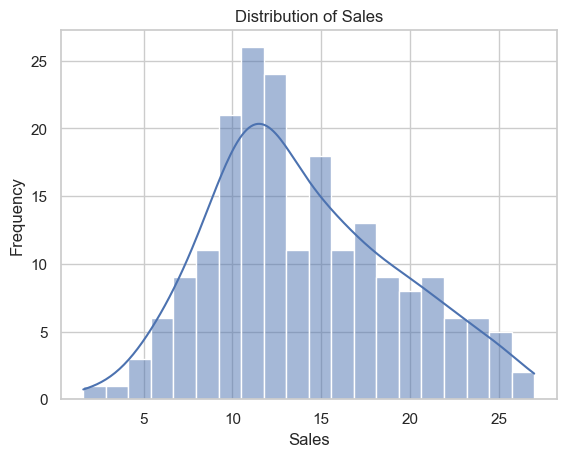

In [7]:
# visualise sales distribution 
sns.histplot(data = df, x = "Sales", bins = 20, kde = True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

The Sales distribution has a skewness coefficient of approximately **0.408**, indicating a slight positive (right) skewness.

This agrees with the descriptive statistics, where the mean (14.02) is greater than the median (12.90).

**Observation:** The Sales distribution is relatively close to symmetric but has a slight tendency towards higher values.

### 4.2 Pairplot of all features

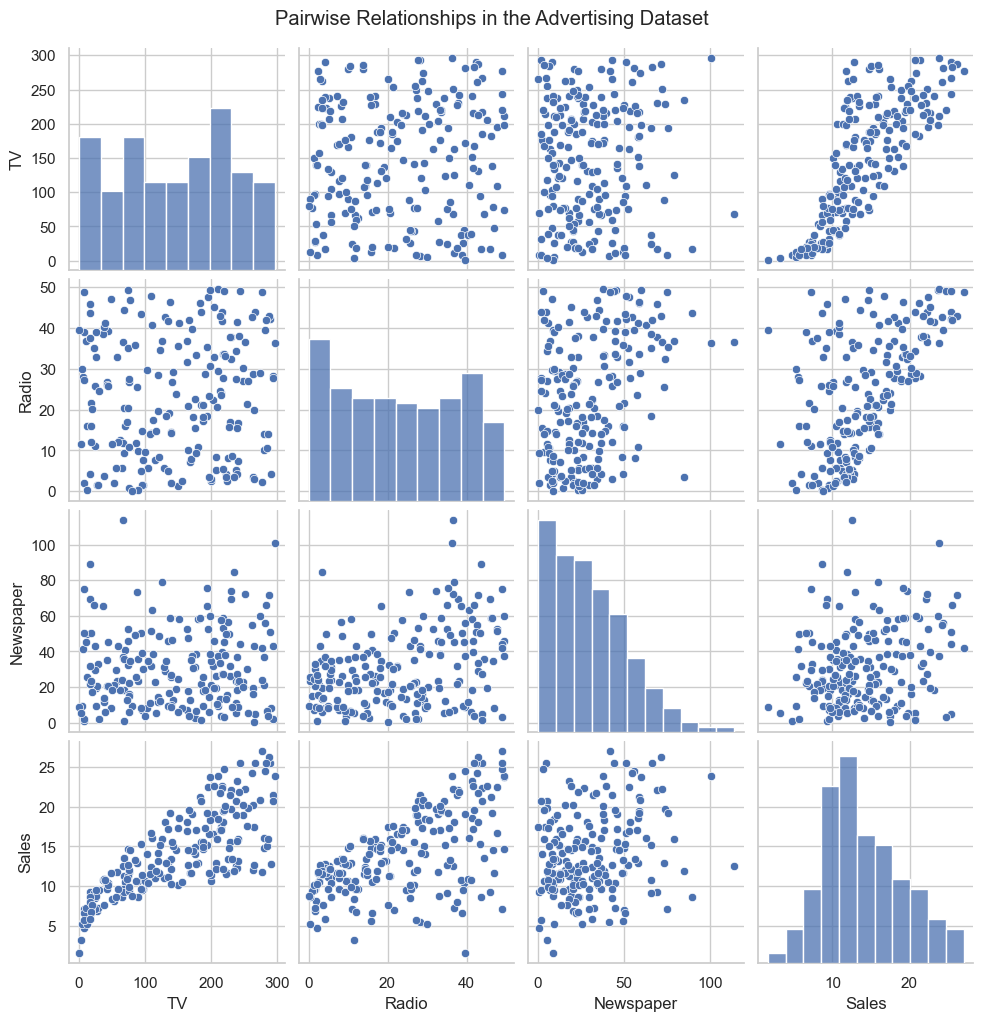

In [8]:
# pairplot
sns.pairplot(df, diag_kind="hist")
plt.suptitle("Pairwise Relationships in the Advertising Dataset", y=1.02)
plt.show()

The pairplot shows the distributions and relationships between all numerical variables.

- **TV and Sales:** Show a strong positive relationship.
- **Radio and Sales:** Show a moderate positive relationship.
- **Newspaper and Sales:** Show a weak relationship.

**Observation:** TV advertising appears to have the strongest relationship with Sales, followed by Radio.

### 4.3 Sales versus each advertising channel

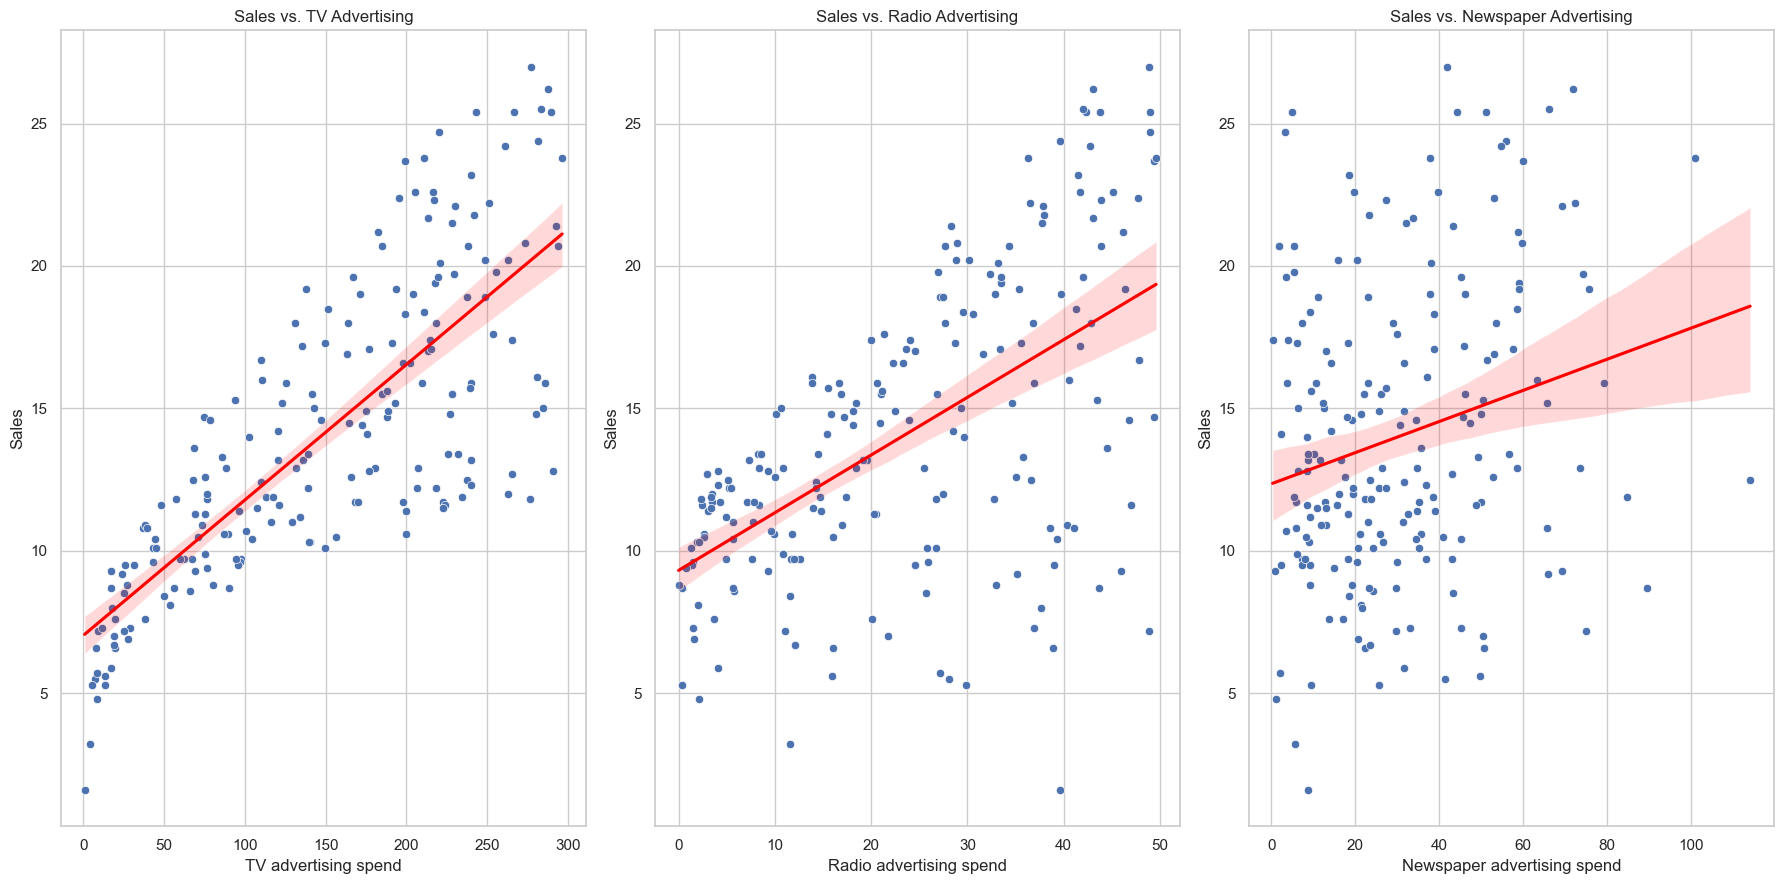

In [9]:
# scatter plot 
fig, axes = plt.subplots(1, 3, figsize=(18, 9))

channels = ["TV", "Radio", "Newspaper"]
for ax, channel in zip(axes, channels):
    sns.scatterplot(data=df, x=channel, y="Sales", ax=ax)
    sns.regplot(data=df, x=channel, y="Sales", scatter=False, ax=ax, color="red")
    ax.set_title(f"Sales vs. {channel} Advertising")
    ax.set_xlabel(f"{channel} advertising spend")
    ax.set_ylabel("Sales")

plt.tight_layout()
plt.show()

The scatter plots illustrate the relationship between each advertising channel and Sales.

- **TV:** Shows a strong positive linear relationship with Sales.
- **Radio:** Shows a moderate positive relationship with Sales.
- **Newspaper:** Shows a weak positive relationship with Sales, with considerable data dispersion.

**Observation:** TV and Radio advertising appear more strongly associated with Sales than Newspaper advertising.

### 4.4 Correlation matrix heatmap

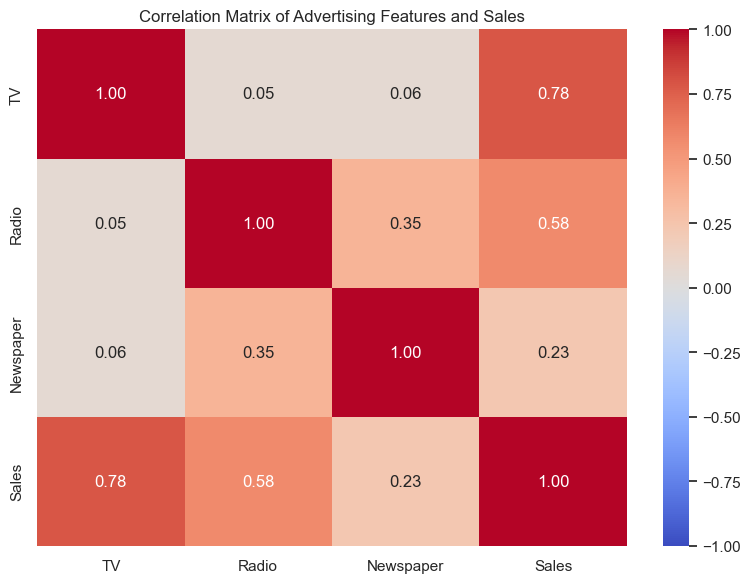

Correlation with Sales:


,Correlation with Sales
TV,0.782224
Radio,0.576223
Newspaper,0.228299


In [10]:
# correlation visualisation 
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Matrix of Advertising Features and Sales")
plt.tight_layout()
plt.show()

print("Correlation with Sales:")
display(correlation_matrix["Sales"].drop("Sales").sort_values(ascending=False).to_frame("Correlation with Sales"))

The correlation heatmap show the strength and direction of the linear relationship between advertising expenditure and Sales.
- TV (0.782): Strong positive correlation with Sales.
- Radio (0.576): Moderate positive correlation with Sales.
- Newspaper (0.228): Weak positive correlation with Sales.
Observation: TV advertising has the strongest positive correlation with Sales, followed by Radio and Newspaper. This suggests that TV advertising expenditure is the strongest individual linear predictor of Sales among the three channels.

# 5. Define features and target, then split the data

In [11]:
# split the data into features and target 
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# display rows and columns of split 
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (160, 3)
Testing features: (40, 3)
Training target: (160,)
Testing target: (40,)


### Train-Test Split Summary

- **Training Set:** 160 observations with 3 features.
- **Testing Set:** 40 observations with 3 features.
- **Target Variables:** 160 training values and 40 testing values.

**Observation:** The dataset has been successfully split, providing sufficient training data for model development and testing data for evaluating model performance.

# 6. Train regression models

### 6.1 Baseline: Linear Regression

In [12]:
# linear regression model 
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression intercept:", round(linear_model.intercept_, 4))
print("Linear Regression coefficients:")
display(pd.Series(linear_model.coef_, index=X.columns, name="Coefficient").to_frame())

Linear Regression intercept: 2.9791
Linear Regression coefficients:


,Coefficient
TV,0.044730
Radio,0.189195
Newspaper,0.002761


- **Intercept (2.9791):** Predicted Sales when all advertising expenditures are zero.
- **TV (0.0447):** Positive relationship with Sales.
- **Radio (0.1892):** Positive relationship with Sales.
- **Newspaper (0.0028):** Very weak positive relationship with Sales.

**Observation:** Radio has the largest regression coefficient, while Newspaper has the smallest, holding other variables constant.

### 6.2 Random Forest Regressor

In [13]:
# random forest regression 
random_forest_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)
random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


# 7. Evaluate and compare the models

In [14]:
def evaluate_regression_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }


In [15]:
results = pd.DataFrame([
    evaluate_regression_model("Linear Regression", y_test, linear_predictions),
    evaluate_regression_model("Random Forest", y_test, rf_predictions)
]).sort_values("RMSE")

In [16]:
display(results.round(4))

best_model_name = results.iloc[0]["Model"]
print("Best model based on test RMSE:", best_model_name)

best_model = linear_model if best_model_name == "Linear Regression" else random_forest_model
best_predictions = linear_predictions if best_model_name == "Linear Regression" else rf_predictions

,Model,MAE,RMSE,R²
1,Random Forest,0.6131,0.7403,0.9826
0,Linear Regression,1.4608,1.7816,0.8994


Best model based on test RMSE: Random Forest


- **Random Forest:** Achieved an R² of 0.9826 and RMSE of 0.7403, indicating better predictive performance.
- **Linear Regression:** Achieved an R² of 0.8994 and RMSE of 1.7816.

**Observation:** Random Forest outperformed Linear Regression, with lower prediction errors and a higher R² score. It is the best-performing model based on test RMSE.

# 8. Actual versus predicted sales

This section compares the actual Sales values with the predictions from the best-performing model (Random Forest) to assess its predictive accuracy.

,Actual Sales,Predicted Sales
0,16.9,17.73
1,22.4,21.74
2,21.4,20.87
3,7.3,6.82
4,24.7,23.10
5,12.6,13.47
6,22.3,22.50
7,8.4,9.67
8,11.5,11.85
9,14.9,15.55


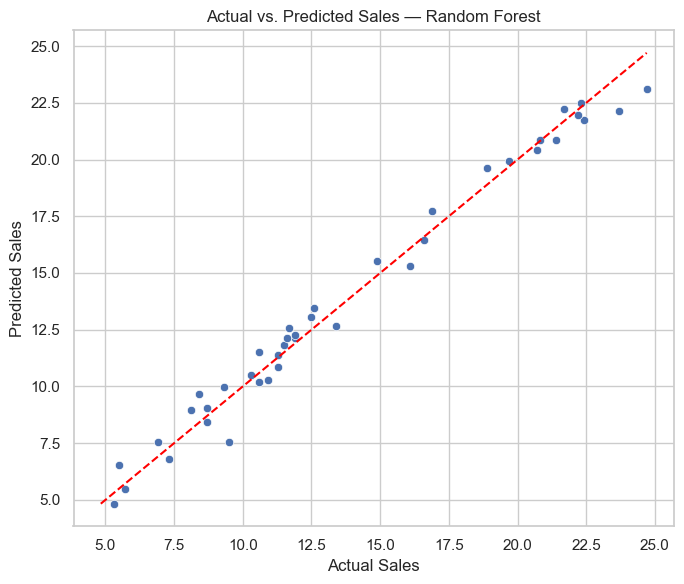

In [17]:
# compare actual and predicted sales 
prediction_comparison = pd.DataFrame({
    "Actual Sales": y_test.to_numpy(),
    "Predicted Sales": best_predictions
})

# display the first 10 comparison
display(prediction_comparison.head(10).round(2))

# visualise actual vs predicted 
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions)
lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())
plt.plot([lower, upper], [lower, upper], linestyle="--", color="red")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title(f"Actual vs. Predicted Sales — {best_model_name}")
plt.tight_layout()
plt.show()

# 9. Residual analysis for the best model

This section examines the residuals of the best-performing model (Random Forest) to assess prediction errors and identify possible patterns in the model's performance.

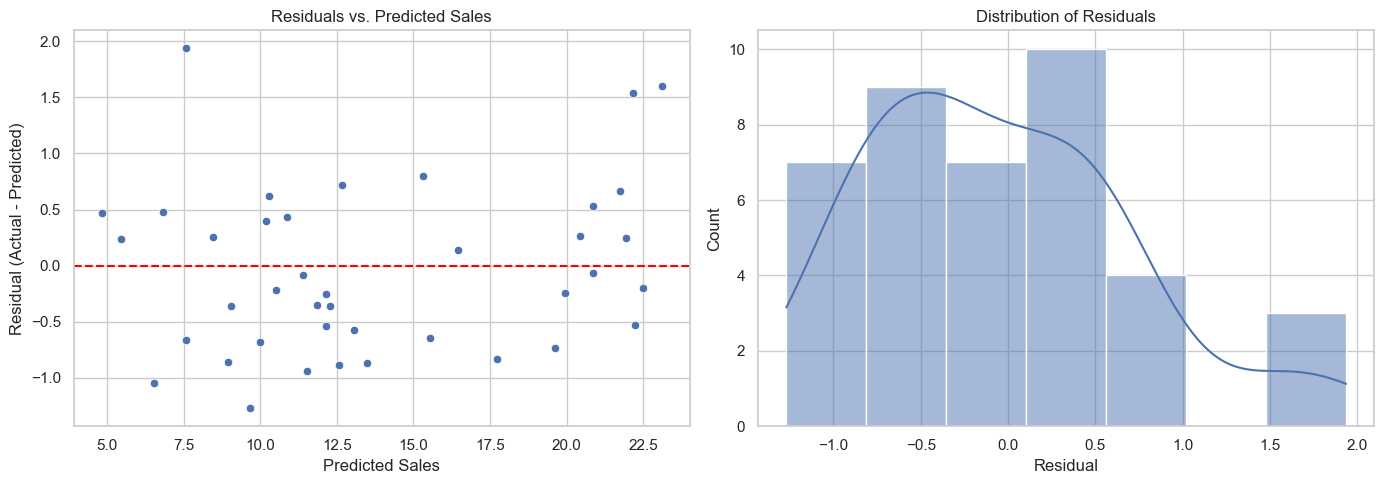

In [18]:
# calculate residuals
residuals = y_test.to_numpy() - best_predictions

# create a subplot for residual analysis 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# scatter plot residuals vs predicted 
sns.scatterplot(x=best_predictions, y=residuals, ax=axes[0])
axes[0].axhline(0, linestyle="--", color="red")
axes[0].set_title("Residuals vs. Predicted Sales")
axes[0].set_xlabel("Predicted Sales")
axes[0].set_ylabel("Residual (Actual - Predicted)")

# visualise the distribution of residuals
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()

### Interpretation of Residual Analysis

- **Residuals vs. Predicted Sales:** Residuals are scattered around zero without a strong visible pattern.
- **Distribution of Residuals:** Most residuals are relatively close to zero, indicating small prediction errors.

**Observation:** The Random Forest model shows good predictive performance, although a few larger residuals are present.

# 10. Which advertising channel has the highest impact?

Linear Regression coefficients (ranked by absolute magnitude):


,Linear Regression Coefficient
Radio,0.189195
TV,0.044730
Newspaper,0.002761


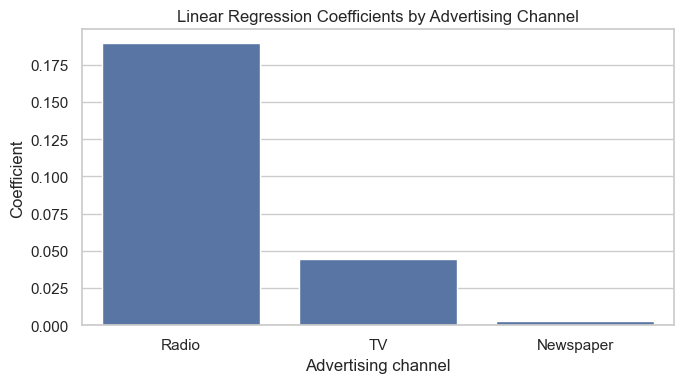

Random Forest feature importance:


,Random Forest Feature Importance
TV,0.625447
Radio,0.361745
Newspaper,0.012808


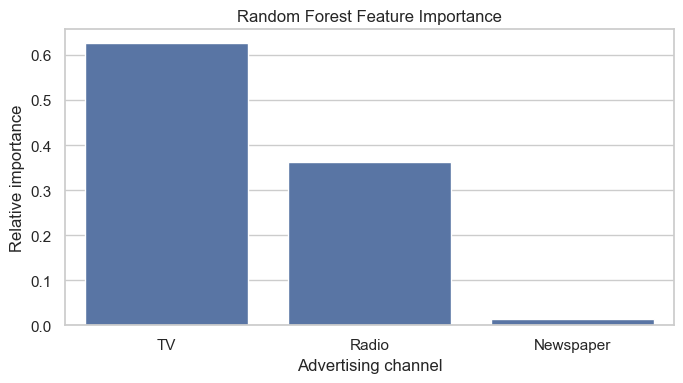

In [19]:
# Linear Regression coefficients show the expected change in predicted sales
# for a one-unit increase in a channel, holding the other channels constant.
coefficient_table = pd.Series(
    linear_model.coef_,
    index=X.columns,
    name="Linear Regression Coefficient"
).sort_values(key=lambda s: s.abs(), ascending=False)

print("Linear Regression coefficients (ranked by absolute magnitude):")
display(coefficient_table.to_frame())

plt.figure(figsize=(7, 4))
sns.barplot(x=coefficient_table.index, y=coefficient_table.values)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Linear Regression Coefficients by Advertising Channel")
plt.xlabel("Advertising channel")
plt.ylabel("Coefficient")
plt.tight_layout()
plt.show()

# Random Forest importance is a complementary, model-specific measure.
rf_importance = pd.Series(
    random_forest_model.feature_importances_,
    index=X.columns,
    name="Random Forest Feature Importance"
).sort_values(ascending=False)

print("Random Forest feature importance:")
display(rf_importance.to_frame())

plt.figure(figsize=(7, 4))
sns.barplot(x=rf_importance.index, y=rf_importance.values)
plt.title("Random Forest Feature Importance")
plt.xlabel("Advertising channel")
plt.ylabel("Relative importance")
plt.tight_layout()
plt.show()

### Interpretation of Linear Regression Coefficients

- Radio (0.1892): Has the largest coefficient.
- TV (0.0447): Has the second-largest coefficient.
- Newspaper (0.0028): Has the smallest coefficient.
Observation: Radio has the strongest coefficient, holding other variables constant.

### Interpretation of Random Forest Feature Importance

- TV (62.54%): Most important feature.
- Radio (36.17%): Second most important.
- Newspaper (1.28%): Least important.
Observation: TV contributes the most to the Random Forest model's predictions.

# 11. Final conclusion

This project developed and compared Linear Regression and Random Forest models to predict Sales using TV, Radio, and Newspaper advertising expenditure.

In [20]:
print("Model comparison:")
display(results.round(4))

print(f"Best model by test RMSE: {best_model_name}")
print("\nCorrelation with Sales:")
display(correlation_matrix["Sales"].drop("Sales").sort_values(ascending=False).to_frame("Correlation"))

print("\nLinear Regression coefficients:")
display(coefficient_table.to_frame())

print("\nRandom Forest feature importance:")
display(rf_importance.to_frame())

Model comparison:


,Model,MAE,RMSE,R²
1,Random Forest,0.6131,0.7403,0.9826
0,Linear Regression,1.4608,1.7816,0.8994


Best model by test RMSE: Random Forest

Correlation with Sales:


,Correlation
TV,0.782224
Radio,0.576223
Newspaper,0.228299



Linear Regression coefficients:


,Linear Regression Coefficient
Radio,0.189195
TV,0.044730
Newspaper,0.002761



Random Forest feature importance:


,Random Forest Feature Importance
TV,0.625447
Radio,0.361745
Newspaper,0.012808


- **Best-performing Model:** Random Forest, with the lowest test RMSE.
- **Test Performance:** MAE = 0.6131, RMSE = 0.7403, and R² = 0.9826.
- **Most Influential Channel:** TV, with 62.54% Random Forest feature importance.
- **Residual Analysis:** Residuals are generally scattered around zero, indicating good predictive performance.
- **Business Recommendation:** Prioritise TV and Radio advertising when planning advertising expenditure, using the model as a decision-support tool rather than proof of causation.

### Limitations

The dataset contains only 200 observations and three advertising channels. Results may vary with different data splits. More data and cross-validation are recommended to assess the model's generalisation performance.

**Overall, Random Forest outperformed Linear Regression and demonstrated strong predictive performance on the test dataset.**